# Correction — Preprocessing sans fuite

Une solution met l'imputation, la standardisation et l'encodage dans une `ColumnTransformer` ajustée sur le train. Le graphique final rend visibles les trous de données et la différence entre une statistique licite et une statistique contaminée par le test.

## Pourquoi le split précède le fit

La médiane de chaque variable numérique, la moyenne et l'écart-type du scaler, ainsi que les catégories d'un `OneHotEncoder`, sont appris lors de `fit`. Le pipeline protège le test si on appelle `fit(x_train, y_train)` puis seulement `predict(x_test)`. `handle_unknown='ignore'` permet de recevoir une catégorie imprévue ; il ne garantit pas que la prédiction restera fiable pour cette catégorie.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
data = load_iris(as_frame=True); X = data.data.copy(); y = data.target
X['size_group'] = np.where(X['sepal length (cm)'] > 5.8, 'large', 'small')
X.loc[X.index[::17], 'sepal width (cm)'] = np.nan
print(X.dtypes); print(y.value_counts(normalize=True).round(2))
x_train, x_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=3)
numeric = list(data.feature_names); categorical = ['size_group']
prep = ColumnTransformer([('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numeric), ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore')), categorical)])
model = make_pipeline(prep, LogisticRegression(max_iter=1000)).fit(x_train, y_train)
print('test accuracy:', model.score(x_test, y_test))
unknown = x_test.iloc[:1].copy(); unknown['size_group'] = 'unseen'
print('unknown category accepted:', model.predict(unknown))
demo_train = pd.Series([1., 2., 4., 5.]); demo_test = pd.Series([100., 120.])
print('train median:', demo_train.median(), '| illegal global median:', pd.concat([demo_train, demo_test]).median())


## Visualiser les trous et la fuite

À gauche, chaque ligne représente une fleur et chaque colonne numérique une mesure : un carré sombre indique une valeur manquante. À droite, la médiane change quand les valeurs test extrêmes entrent dans le calcul. Cet exemple rend la fuite visible ; dans un jeu réel, elle peut être moins évidente.

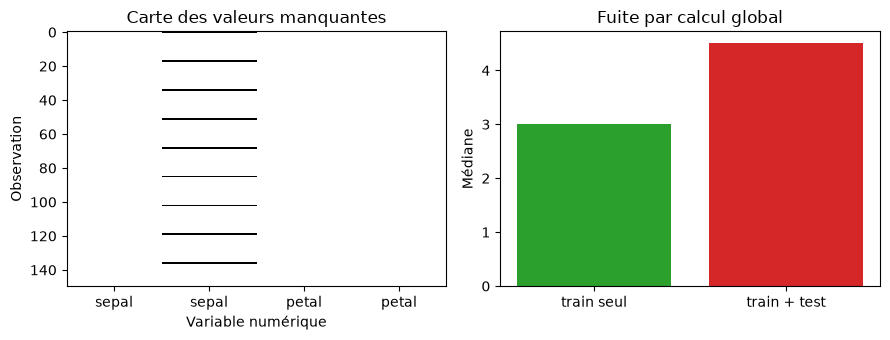

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].imshow(X[numeric].isna().to_numpy(), aspect='auto', cmap='Greys', interpolation='nearest')
axes[0].set(xlabel='Variable numérique', ylabel='Observation', title='Carte des valeurs manquantes', xticks=range(len(numeric)), xticklabels=[name.split(' ')[0] for name in numeric])
axes[1].bar(['train seul', 'train + test'], [demo_train.median(), pd.concat([demo_train, demo_test]).median()], color=['tab:green', 'tab:red'])
axes[1].set(ylabel='Médiane', title='Fuite par calcul global')
plt.tight_layout(); plt.show()

## Interprétation et limite

La médiane de train seul est la seule disponible au moment où l'on prépare le modèle. Un résultat test élevé n'est interprétable que si tous les choix ont été faits sans exploiter le test. La variable `size_group` est dérivée d'une mesure déjà présente ; elle ne constitue pas une source d'information indépendante.